In [51]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [52]:
class BatsmanState(TypedDict):

    runs: int
    balls: int
    fours: int
    sixes: int

    sr: float
    bpb: float
    boundaryPercent : float
    summary: str

In [53]:
graph = StateGraph(BatsmanState)

In [54]:
def CalculateSR(state: BatsmanState):
    sr = (state['runs']/state['balls'])*100
    
    return {'sr':sr}

In [55]:
def CalculateBPB(state: BatsmanState):
    bpb = (state['balls']/state['sixes']+state['fours'])
    
    return {'bpb': bpb}


In [57]:
def CalculateBper(state: BatsmanState):
    boundaryPercent = (((state['fours']*4) + (state['sixes']*6)) /state['runs'])*100
    
    return {'boundaryPercent': boundaryPercent}

In [58]:
def Summary(state: BatsmanState):
    summary = f"""
Strike Rate - {state['sr']}\n
Balls per boundary - {state['bpb']}\n
Boundary Percent - {state['boundaryPercent']}\n
"""
    
    return {'summary': summary}

In [59]:
# add nodes
graph.add_node('calculateSR', CalculateSR)
graph.add_node('calculateBPB', CalculateBPB)
graph.add_node('calculateBper', CalculateBper)
graph.add_node('Summary', Summary)

In [60]:
# add edges

graph.add_edge(START, 'calculateSR')
graph.add_edge(START, 'calculateBPB')
graph.add_edge(START, 'calculateBper')

graph.add_edge('calculateSR', 'Summary')
graph.add_edge('calculateBPB', 'Summary')
graph.add_edge('calculateBper', 'Summary')

graph.add_edge('Summary', END)

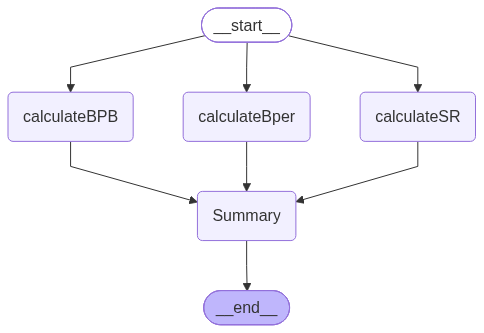

In [61]:
graph.compile()

In [62]:
workflow = graph.compile()

In [63]:
initialState = {
    'runs': 100,
    'balls': 50,
    'fours': 6,
    'sixes': 4
}

In [64]:
workflow.invoke(initialState)

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 4,
 'sr': 200.0,
 'bpb': 18.5,
 'boundaryPercent': 48.0,
 'summary': '\nStrike Rate - 200.0\n\nBalls per boundary - 18.5\n\nBoundary Percent - 48.0\n\n'}